<a href="https://colab.research.google.com/github/Valeria1100/Confiabilidad-y-planeaci-n-de-capacidad-de-un-servicio-de-inferencia-de-IA./blob/main/Punto_E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte E — Monitoreo y decisión de alertas

**E1.** Estime con intervalos de confianza la sensibilidad y la tasa de falsos positivos de D1,
de D2 y de las reglas combinadas “D1 y D2” y “D1 o D2”.

In [209]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Parámetros personalizados del grupo
S = 4063981172

t1 = 80 + 10 * (S % 5)
t2 = 400 + 25 * (S % 5)

# Nivel de confianza del 99%
confianza = 0.99
alpha = 1 - confianza

print("t1:", t1, "KB")
print("t2:", t2, "KB")
print("Nivel de confianza:", confianza)

In [210]:
# Cargamos el archivo de monitoreo
monitoreo = pd.read_csv("monitoreo.csv")

# Creamos una copia para trabajar
datos_e1 = monitoreo.copy()

# Revisamos los primeros registros
display(datos_e1.head())

# Revisamos si existen datos faltantes
print("Datos faltantes:")
print(datos_e1[["D1", "D2", "incidente"]].isnull().sum())

# Revisamos los valores de D1
print("\nValores de D1:")
print(datos_e1["D1"].value_counts(dropna=False))

# Revisamos los valores de D2
print("\nValores de D2:")
print(datos_e1["D2"].value_counts(dropna=False))

# Revisamos los valores de los incidentes
print("\nValores de incidente:")
print(datos_e1["incidente"].value_counts(dropna=False))

,minuto,D1,D2,incidente
0,1,0,0,0
1,2,0,0,0
2,3,1,1,1
3,4,0,0,0
4,5,0,0,0


Datos faltantes:
D1           0
D2           0
incidente    0
dtype: int64

Valores de D1:
D1
0    5351
1     649
Name: count, dtype: int64

Valores de D2:
D2
0    5435
1     565
Name: count, dtype: int64

Valores de incidente:
incidente
0    5310
1     690
Name: count, dtype: int64


In [211]:
# Eliminamos los registros que tengan datos faltantes
datos_e1 = datos_e1.dropna(
    subset=["D1", "D2", "incidente"]
).copy()

# Convertimos las columnas a números enteros
datos_e1["D1"] = datos_e1["D1"].astype(int)
datos_e1["D2"] = datos_e1["D2"].astype(int)
datos_e1["incidente"] = datos_e1["incidente"].astype(int)

# Creamos la regla D1 y D2
datos_e1["D1_y_D2"] = (
    (datos_e1["D1"] == 1) &
    (datos_e1["D2"] == 1)
).astype(int)

# Creamos la regla D1 o D2
datos_e1["D1_o_D2"] = (
    (datos_e1["D1"] == 1) |
    (datos_e1["D2"] == 1)
).astype(int)

# Revisamos la cantidad de minutos utilizados
print("Cantidad de minutos utilizados:", len(datos_e1))

# Revisamos cuántos minutos tuvieron incidentes
print("\nEstado real del sistema:")
print(datos_e1["incidente"].value_counts().sort_index())

Cantidad de minutos utilizados: 6000

Estado real del sistema:
incidente
0    5310
1     690
Name: count, dtype: int64


In [212]:
# Definimos la semilla del grupo
S = 4063981172


# Calculamos el nivel de confianza
if S % 3 == 0:
    confianza = 0.90
elif S % 3 == 1:
    confianza = 0.95
else:
    confianza = 0.99


# Calculamos el nivel de significancia
alpha = 1 - confianza


# Mostramos los resultados
print("Residuo de S al dividir entre 3:", S % 3)
print("Nivel de confianza:", confianza * 100, "%")
print("Nivel de significancia:", alpha)

Residuo de S al dividir entre 3: 2
Nivel de confianza: 99.0 %
Nivel de significancia: 0.010000000000000009


In [213]:
# Importamos la distribución normal de SciPy
from scipy.stats import norm


# Creamos una función para calcular el intervalo de Wilson
def intervalo_wilson(exitos, total, confianza):
    # Calculamos la proporción observada
    p = exitos / total
    # Calculamos el valor crítico según la confianza
    z = norm.ppf(1 - (1 - confianza) / 2)
    # Calculamos el denominador
    denominador = 1 + (z**2 / total)
    # Calculamos el centro del intervalo
    centro = (
        p + z**2 / (2 * total)
    ) / denominador

    # Calculamos el margen del intervalo
    margen = (
        z * np.sqrt(
            (p * (1 - p) / total) +
            (z**2 / (4 * total**2))
        ) / denominador
    )

    # Calculamos los límites
    limite_inferior = centro - margen
    limite_superior = centro + margen
    return limite_inferior, limite_superior

In [214]:
# Separamos los minutos con incidentes y sin incidentes
con_incidente = datos_e1[
    datos_e1["incidente"] == 1
]

sin_incidente = datos_e1[
    datos_e1["incidente"] == 0
]

# Definimos las reglas que vamos a evaluar
reglas = ["D1", "D2", "D1_y_D2", "D1_o_D2"]

# Creamos una lista para guardar los resultados
resultados_e1 = []

# Recorremos cada una de las reglas
for regla in reglas:
    # Contamos las alertas cuando sí existía un incidente
    verdaderos_positivos = con_incidente[regla].sum()
    # Contamos las alertas cuando no existía un incidente
    falsos_positivos = sin_incidente[regla].sum()

    # Calculamos la sensibilidad
    total_incidentes = len(con_incidente)
    sensibilidad = verdaderos_positivos / total_incidentes

    # Calculamos el intervalo de confianza de sensibilidad
    ic_sensibilidad = intervalo_wilson(
        verdaderos_positivos,
        total_incidentes,
        confianza
    )

    # Calculamos la tasa de falsos positivos
    total_sin_incidente = len(sin_incidente)
    tasa_falsos_positivos = (
        falsos_positivos / total_sin_incidente
    )

    # Calculamos el intervalo de confianza de falsos positivos
    ic_falsos_positivos = intervalo_wilson(
        falsos_positivos,
        total_sin_incidente,
        confianza
    )

    # Guardamos todos los resultados
    resultados_e1.append({
        "Regla": regla,
        "Sensibilidad": sensibilidad,
        "Sensibilidad inferior": ic_sensibilidad[0],
        "Sensibilidad superior": ic_sensibilidad[1],
        "Tasa falsos positivos": tasa_falsos_positivos,
        "Falsos positivos inferior": ic_falsos_positivos[0],
        "Falsos positivos superior": ic_falsos_positivos[1]
    })

# Convertimos los resultados en una tabla
tabla_e1 = pd.DataFrame(resultados_e1)

# Mostramos los resultados
print("RESULTADOS DE SENSIBILIDAD Y FALSOS POSITIVOS")
display(tabla_e1.round(5))

RESULTADOS DE SENSIBILIDAD Y FALSOS POSITIVOS


,Regla,Sensibilidad,Sensibilidad inferior,Sensibilidad superior,Tasa falsos positivos,Falsos positivos inferior,Falsos positivos superior
0,D1,0.87391,0.83776,0.90294,0.00866,0.00595,0.01261
1,D2,0.76087,0.71668,0.80009,0.00753,0.00503,0.01126
2,D1_y_D2,0.66232,0.61459,0.70695,0.00151,0.00062,0.00363
3,D1_o_D2,0.97246,0.95137,0.98456,0.01469,0.01100,0.01959


In [215]:
# Creamos una copia de la tabla original
tabla_e1_porcentajes = tabla_e1.copy()

# Identificamos las columnas que vamos a convertir
columnas_porcentaje = [
    "Sensibilidad",
    "Sensibilidad inferior",
    "Sensibilidad superior",
    "Tasa falsos positivos",
    "Falsos positivos inferior",
    "Falsos positivos superior"
]

# Convertimos las proporciones a porcentajes
for columna in columnas_porcentaje:

    tabla_e1_porcentajes[columna] = (
        tabla_e1_porcentajes[columna] * 100
    ).round(2)

# Mostramos la tabla final
print("TABLA FINAL E1 - RESULTADOS EN PORCENTAJES")
display(tabla_e1_porcentajes)

TABLA FINAL E1 - RESULTADOS EN PORCENTAJES


,Regla,Sensibilidad,Sensibilidad inferior,Sensibilidad superior,Tasa falsos positivos,Falsos positivos inferior,Falsos positivos superior
0,D1,87.39,83.78,90.29,0.87,0.59,1.26
1,D2,76.09,71.67,80.01,0.75,0.50,1.13
2,D1_y_D2,66.23,61.46,70.70,0.15,0.06,0.36
3,D1_o_D2,97.25,95.14,98.46,1.47,1.10,1.96


**E2.** Calcule, para producción (con la prevalencia π de su grupo), la probabilidad de que
haya un incidente real dado cada una de las cuatro reglas de alerta. Explique por qué estas cifras
difieren de las que se obtendrían directamente de monitoreo.csv.


In [216]:
# Definimos la semilla asignada a nuestro grupo
S = 4063981172

# Calculamos la prevalencia de incidentes en producción
pi = (4 + (S % 6)) / 1000

# Mostramos los resultados
print("Residuo de S al dividir entre 6:", S % 6)
print("Prevalencia de producción:", pi)
print("Prevalencia en porcentaje:", round(pi * 100, 2), "%")

Residuo de S al dividir entre 6: 2
Prevalencia de producción: 0.006
Prevalencia en porcentaje: 0.6 %


In [217]:
# Creamos una lista para guardar los resultados
resultados_e2 = []

# Recorremos las cuatro reglas de alerta de E1
for i, fila in tabla_e1.iterrows():

    # Tomamos la sensibilidad y la tasa de falsos positivos
    sensibilidad = fila["Sensibilidad"]
    tasa_falsos_positivos = fila["Tasa falsos positivos"]

    # Calculamos el numerador de Bayes
    numerador = sensibilidad * pi

    # Calculamos el denominador de Bayes
    denominador = (
        sensibilidad * pi +
        tasa_falsos_positivos * (1 - pi)
    )

    # Calculamos la probabilidad de incidente real dada una alerta
    if denominador > 0:
        probabilidad_incidente = numerador / denominador
    else:
        probabilidad_incidente = np.nan

    # Guardamos los resultados
    resultados_e2.append({
        "Regla": fila["Regla"],
        "Sensibilidad": sensibilidad,
        "Tasa falsos positivos": tasa_falsos_positivos,
        "Probabilidad de incidente": probabilidad_incidente
    })

# Creamos la tabla final
tabla_e2 = pd.DataFrame(resultados_e2)

# Mostramos los resultados
print("PROBABILIDAD DE INCIDENTE REAL DADA UNA ALERTA")
display(tabla_e2.round(5))

PROBABILIDAD DE INCIDENTE REAL DADA UNA ALERTA


,Regla,Sensibilidad,Tasa falsos positivos,Probabilidad de incidente
0,D1,0.87391,0.00866,0.37847
1,D2,0.76087,0.00753,0.37876
2,D1_y_D2,0.66232,0.00151,0.72630
3,D1_o_D2,0.97246,0.01469,0.28552


In [218]:
# Creamos una copia de la tabla de resultados
tabla_e2_porcentajes = tabla_e2.copy()

# Convertimos las probabilidades a porcentajes
tabla_e2_porcentajes["Probabilidad de incidente"] = (
    tabla_e2_porcentajes["Probabilidad de incidente"] * 100
).round(2)

# Mostramos la tabla final
print("RESULTADOS FINALES E2 - PORCENTAJES")
display(tabla_e2_porcentajes)

RESULTADOS FINALES E2 - PORCENTAJES


,Regla,Sensibilidad,Tasa falsos positivos,Probabilidad de incidente
0,D1,0.873913,0.008663,37.85
1,D2,0.760870,0.007533,37.88
2,D1_y_D2,0.662319,0.001507,72.63
3,D1_o_D2,0.972464,0.014689,28.55


**E3.** Verifique con datos, y no por suposición, si D1 y D2 son condicionalmente independientes dado el estado del sistema. Cuantifique el efecto de su conclusión sobre la probabilidad calculada en E2.

In [219]:
datos_e3 = datos_e1.copy()

# Revisamos los datos faltantes
print("Datos faltantes:")
print(datos_e3[['D1', 'D2', 'incidente']].isnull().sum())

# Revisamos la cantidad de registros
print("\nTotal de minutos:")
print(len(datos_e3))

# Definimos el nivel de significancia del grupo
confianza = 0.99
alpha = 1 - confianza
print("\nNivel de confianza:", confianza * 100, "%")
print("Nivel de significancia:", alpha)

Datos faltantes:
D1           0
D2           0
incidente    0
dtype: int64

Total de minutos:
6000

Nivel de confianza: 99.0 %
Nivel de significancia: 0.010000000000000009


In [220]:
# Separamos los minutos sin incidentes
sin_incidente = datos_e3[
    datos_e3['incidente'] == 0
].copy()

# Separamos los minutos con incidentes
con_incidente = datos_e3[
    datos_e3['incidente'] == 1
].copy()

# Mostramos la cantidad de observaciones
print("MINUTOS SIN INCIDENTE:")
print(len(sin_incidente))
print("\nMINUTOS CON INCIDENTE:")
print(len(con_incidente))

MINUTOS SIN INCIDENTE:
5310

MINUTOS CON INCIDENTE:
690


In [221]:
# Importamos la prueba Chi-cuadrado
from scipy.stats import chi2_contingency

# Recorremos los dos estados del sistema
for estado in [0, 1]:
    # Seleccionamos los registros según el estado
    grupo = datos_e3[
        datos_e3['incidente'] == estado
    ]

    # Construimos la tabla de frecuencias entre D1 y D2
    tabla = pd.crosstab(
        grupo['D1'],
        grupo['D2']
    )

    # Organizamos las filas y columnas
    tabla = tabla.reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    )

    # Aplicamos la prueba Chi-cuadrado
    chi2, p_valor, grados, esperados = chi2_contingency(
        tabla,
        correction=False
    )

    if estado == 0:
        print("ESTADO SIN INCIDENTE")
    else:
        print("ESTADO CON INCIDENTE")

    print("Cantidad de observaciones:", len(grupo))
    print("\nTabla de frecuencias:")
    display(tabla)
    print("Chi-cuadrado:", chi2)
    print("Grados de libertad:", grados)
    print("Valor p:", p_valor)
    print("\nFrecuencias esperadas:")

    display(
        pd.DataFrame(
            esperados,
            index=[0, 1],
            columns=[0, 1]
        ).round(2)
    )

    # Tomamos la decisión estadística
    if p_valor < alpha:
        print("\nSe rechaza H0.")
        print("Existe evidencia de dependencia entre D1 y D2.")
    else:
        print("\nNo se rechaza H0.")
        print("No hay evidencia suficiente para descartar independencia.")

ESTADO SIN INCIDENTE
Cantidad de observaciones: 5310

Tabla de frecuencias:


D2,0,1
D1,,
0,5232,32
1,38,8


Chi-cuadrado: 171.81362497551913
Grados de libertad: 1
Valor p: 2.9721087640080735e-39

Frecuencias esperadas:


,0,1
0,5224.35,39.65
1,45.65,0.35



Se rechaza H0.
Existe evidencia de dependencia entre D1 y D2.
ESTADO CON INCIDENTE
Cantidad de observaciones: 690

Tabla de frecuencias:


D2,0,1
D1,,
0,19,68
1,146,457


Chi-cuadrado: 0.23534662855301047
Grados de libertad: 1
Valor p: 0.6275874139205906

Frecuencias esperadas:


,0,1
0,20.8,66.2
1,144.2,458.8



No se rechaza H0.
No hay evidencia suficiente para descartar independencia.


In [222]:
# Calculamos la prevalencia de producción del grupo
S = 4063981172
pi = (4 + (S % 6)) / 1000


# Calculamos las probabilidades individuales sin incidente
p_d1_sin = sin_incidente['D1'].mean()
p_d2_sin = sin_incidente['D2'].mean()

# Calculamos las probabilidades individuales con incidente
p_d1_con = con_incidente['D1'].mean()
p_d2_con = con_incidente['D2'].mean()

# Calculamos la probabilidad conjunta de la regla AND sin incidente
p_and_sin = (
    (sin_incidente['D1'] == 1) &
    (sin_incidente['D2'] == 1)
).mean()

# Calculamos la probabilidad conjunta de la regla AND con incidente
p_and_con = (
    (con_incidente['D1'] == 1) &
    (con_incidente['D2'] == 1)
).mean()

# Calculamos la probabilidad de la regla OR sin incidente
p_or_sin = (
    (sin_incidente['D1'] == 1) |
    (sin_incidente['D2'] == 1)
).mean()

# Calculamos la probabilidad de la regla OR con incidente
p_or_con = (
    (con_incidente['D1'] == 1) |
    (con_incidente['D2'] == 1)
).mean()


# Mostramos las probabilidades observadas
print("PROBABILIDADES CONDICIONALES OBSERVADAS")
print("\nSin incidente:")
print("P(D1 = 1):", p_d1_sin)
print("P(D2 = 1):", p_d2_sin)
print("P(D1 y D2):", p_and_sin)
print("P(D1 o D2):", p_or_sin)
print("\nCon incidente:")
print("P(D1 = 1):", p_d1_con)
print("P(D2 = 1):", p_d2_con)
print("P(D1 y D2):", p_and_con)
print("P(D1 o D2):", p_or_con)

PROBABILIDADES CONDICIONALES OBSERVADAS

Sin incidente:
P(D1 = 1): 0.008662900188323917
P(D2 = 1): 0.007532956685499058
P(D1 y D2): 0.0015065913370998117
P(D1 o D2): 0.014689265536723164

Con incidente:
P(D1 = 1): 0.8739130434782608
P(D2 = 1): 0.7608695652173914
P(D1 y D2): 0.6623188405797101
P(D1 o D2): 0.972463768115942


In [223]:
# Calculamos la probabilidad de AND suponiendo independencia
p_and_sin_ind = p_d1_sin * p_d2_sin
p_and_con_ind = p_d1_con * p_d2_con

# Calculamos la probabilidad de OR suponiendo independencia
p_or_sin_ind = (
    p_d1_sin + p_d2_sin - p_and_sin_ind
)
p_or_con_ind = (
    p_d1_con + p_d2_con - p_and_con_ind
)

# Mostramos los resultados
print("PROBABILIDADES SUPONIENDO INDEPENDENCIA")
print("\nSin incidente:")
print("P(D1 y D2):", p_and_sin_ind)
print("P(D1 o D2):", p_or_sin_ind)
print("\nCon incidente:")
print("P(D1 y D2):", p_and_con_ind)
print("P(D1 o D2):", p_or_con_ind)

PROBABILIDADES SUPONIENDO INDEPENDENCIA

Sin incidente:
P(D1 y D2): 6.525725188944569e-05
P(D1 o D2): 0.016130599621933528

Con incidente:
P(D1 y D2): 0.6649338374291115
P(D1 o D2): 0.9698487712665406


In [224]:
# Creamos una función para calcular la probabilidad posterior de Bayes
def calcular_posterior(sensibilidad, falsos_positivos):
    numerador = sensibilidad * pi
    denominador = (
        sensibilidad * pi +
        falsos_positivos * (1 - pi)
    )
    return numerador / denominador


# Calculamos los resultados utilizando los datos observados
observados = {
    "D1": calcular_posterior(
        p_d1_con,
        p_d1_sin
    ),
    "D2": calcular_posterior(
        p_d2_con,
        p_d2_sin
    ),
    "D1 y D2": calcular_posterior(
        p_and_con,
        p_and_sin
    ),
    "D1 o D2": calcular_posterior(
        p_or_con,
        p_or_sin
    )
}

# Calculamos los resultados suponiendo independencia condicional
independencia = {
    "D1": calcular_posterior(
        p_d1_con,
        p_d1_sin
    ),
    "D2": calcular_posterior(
        p_d2_con,
        p_d2_sin
    ),
    "D1 y D2": calcular_posterior(
        p_and_con_ind,
        p_and_sin_ind
    ),
    "D1 o D2": calcular_posterior(
        p_or_con_ind,
        p_or_sin_ind
    )
}

# Creamos la tabla para comparar los dos resultados
comparacion = pd.DataFrame({
    "Regla": observados.keys(),
    "Con datos observados": observados.values(),
    "Suponiendo independencia": independencia.values()
})


# Calculamos la diferencia en puntos porcentuales
comparacion["Diferencia (p.p.)"] = (
    comparacion["Con datos observados"] -
    comparacion["Suponiendo independencia"]
) * 100

# Convertimos las probabilidades a porcentajes
comparacion["Con datos observados"] *= 100
comparacion["Suponiendo independencia"] *= 100

# Mostramos los resultados
print("COMPARACIÓN DE LAS PROBABILIDADES DE E2")
display(comparacion.round(2))

COMPARACIÓN DE LAS PROBABILIDADES DE E2


,Regla,Con datos observados,Suponiendo independencia,Diferencia (p.p.)
0,D1,37.85,37.85,0.00
1,D2,37.88,37.88,0.00
2,D1 y D2,72.63,98.40,-25.77
3,D1 o D2,28.55,26.63,1.92


**E4.** El equipo de guardia exige que, con probabilidad al menos 0,90, el número de falsas
alarmas en un día (1440 minutos) no supere km´ax. Determine qué reglas cumplen la exigencia,
propague la incertidumbre de la estimación hasta su conclusión y recomiende una regla. Figura 6.


In [225]:
incidente = 0

In [226]:
# E4: Preparamos los datos de monitoreo
datos_e4 = datos_e1.copy()

# Creamos la regla D1 y D2
datos_e4["D1_y_D2"] = (
    (datos_e4["D1"] == 1) &
    (datos_e4["D2"] == 1)
).astype(int)

# Creamos la regla D1 o D2
datos_e4["D1_o_D2"] = (
    (datos_e4["D1"] == 1) |
    (datos_e4["D2"] == 1)
).astype(int)

# Separamos solamente los minutos sin incidentes
sin_incidente = datos_e4[
    datos_e4["incidente"] == 0
].copy()

# Definimos los parámetros del grupo
S = 4063981172
confianza = 0.99
alpha = 1 - confianza

# Calculamos el máximo de falsas alarmas permitido
k_max = 4 + (S % 5)

# Cantidad de minutos de un día
minutos_dia = 1440

# Mostramos los parámetros
print("Minutos sin incidentes:", len(sin_incidente))
print("Máximo de falsas alarmas:", k_max)
print("Minutos de un día:", minutos_dia)
print("Nivel de confianza:", confianza * 100, "%")

Minutos sin incidentes: 5310
Máximo de falsas alarmas: 6
Minutos de un día: 1440
Nivel de confianza: 99.0 %


In [227]:
# Importamos las distribuciones necesarias de SciPy
from scipy.stats import norm, betabinom

# Definimos las cuatro reglas de alerta
reglas = [
    "D1",
    "D2",
    "D1_y_D2",
    "D1_o_D2"
]

# Obtenemos la cantidad de minutos sin incidentes
n = len(sin_incidente)

# Calculamos el valor crítico de Wilson para el 99%
z = norm.ppf(1 - alpha / 2)

# Creamos una lista para guardar los resultados
resultados_e4 = []

# Recorremos cada regla
for regla in reglas:
    # Contamos las falsas alarmas observadas
    x = int(sin_incidente[regla].sum())
    # Calculamos la tasa de falsas alarmas
    tasa = x / n

    # Calculamos el denominador del intervalo Wilson
    denominador = 1 + z**2 / n

    # Calculamos el centro del intervalo
    centro = (
        tasa + z**2 / (2 * n)
    ) / denominador

    # Calculamos el margen del intervalo
    margen = (
        z * np.sqrt(
            tasa * (1 - tasa) / n +
            z**2 / (4 * n**2)
        ) / denominador
    )

    # Calculamos los límites del intervalo
    limite_inferior = centro - margen
    limite_superior = centro + margen

    # Guardamos los resultados
    resultados_e4.append({
        "Regla": regla,
        "Falsas alarmas observadas": x,
        "Tasa estimada": tasa,
        "Límite inferior 99%": limite_inferior,
        "Límite superior 99%": limite_superior
    })

# Creamos la tabla de resultados
tabla_tasas_e4 = pd.DataFrame(resultados_e4)

# Mostramos los resultados
print("TASAS DE FALSAS ALARMAS E INTERVALOS WILSON")
display(tabla_tasas_e4.round(6))

TASAS DE FALSAS ALARMAS E INTERVALOS WILSON


,Regla,Falsas alarmas observadas,Tasa estimada,Límite inferior 99%,Límite superior 99%
0,D1,46,0.008663,0.005945,0.012607
1,D2,40,0.007533,0.005032,0.011263
2,D1_y_D2,8,0.001507,0.000624,0.003633
3,D1_o_D2,78,0.014689,0.011002,0.019588


In [228]:
# Creamos una lista para guardar las probabilidades diarias
resultados_probabilidad = []

# Recorremos las cuatro reglas
for i, fila in tabla_tasas_e4.iterrows():
    # Obtenemos los datos de cada regla
    regla = fila["Regla"]
    x = fila["Falsas alarmas observadas"]
    limite_superior = fila["Límite superior 99%"]

    # Distribución Beta posterior con prior de Jeffreys
    a = x + 0.5
    b = n - x + 0.5

    # Calculamos la probabilidad predictiva de no superar
    # las 6 falsas alarmas durante los 1440 minutos
    probabilidad_cumplir = betabinom.cdf(
        k_max,
        minutos_dia,
        a,
        b
    )

    # Realizamos una comprobación conservadora usando
    # el límite superior del intervalo Wilson
    a_conservador = (
        n * limite_superior + 0.5
    )

    b_conservador = (
        n * (1 - limite_superior) + 0.5
    )

    # Calculamos la probabilidad en el escenario conservador
    probabilidad_conservadora = betabinom.cdf(
        k_max,
        minutos_dia,
        a_conservador,
        b_conservador
    )

    # Guardamos los resultados
    resultados_probabilidad.append({
        "Regla": regla,
        "P(N <= 6)": probabilidad_cumplir,
        "P(N <= 6) conservadora": probabilidad_conservadora
    })

# Creamos la tabla final
tabla_e4 = pd.DataFrame(resultados_probabilidad)

# Mostramos los resultados
print("PROBABILIDAD DE CUMPLIR EL REQUISITO DIARIO")
display(tabla_e4.round(6))

PROBABILIDAD DE CUMPLIR EL REQUISITO DIARIO


,Regla,P(N <= 6),P(N <= 6) conservadora
0,D1,0.049061,0.002141
1,D2,0.105400,0.006650
2,D1_y_D2,0.979461,0.696641
3,D1_o_D2,0.000333,0.000003


In [229]:
# Creamos una copia de los resultados
tabla_e4_final = tabla_tasas_e4.merge(
    tabla_e4,
    on="Regla"
)

# Convertimos las columnas de probabilidades a porcentajes
columnas_porcentaje = [
    "Tasa estimada",
    "Límite inferior 99%",
    "Límite superior 99%",
    "P(N <= 6)",
    "P(N <= 6) conservadora"
]

# Multiplicamos por 100
for columna in columnas_porcentaje:

    tabla_e4_final[columna] = (
        tabla_e4_final[columna] * 100
    )

# Redondeamos los resultados
tabla_e4_final = tabla_e4_final.round(4)

# Mostramos la tabla
print("RESULTADOS FINALES E4")
display(tabla_e4_final)

RESULTADOS FINALES E4


,Regla,Falsas alarmas observadas,Tasa estimada,Límite inferior 99%,Límite superior 99%,P(N <= 6),P(N <= 6) conservadora
0,D1,46,0.8663,0.5945,1.2607,4.9061,0.2141
1,D2,40,0.7533,0.5032,1.1263,10.5400,0.6650
2,D1_y_D2,8,0.1507,0.0624,0.3633,97.9461,69.6641
3,D1_o_D2,78,1.4689,1.1002,1.9588,0.0333,0.0003


In [230]:
# Definimos el requisito mínimo del equipo de guardia
requisito = 0.90

# Creamos una copia para evaluar el cumplimiento
evaluacion_e4 = tabla_e4.copy()

# Revisamos si cada regla cumple el 90% en el cálculo predictivo
evaluacion_e4["Cumple central"] = (
    evaluacion_e4["P(N <= 6)"] >= requisito
)

# Revisamos si cumple en el escenario conservador
evaluacion_e4["Cumple conservador"] = (
    evaluacion_e4["P(N <= 6) conservadora"] >= requisito
)

# Mostramos los resultados
print("EVALUACIÓN DEL REQUISITO DEL 90%")
display(evaluacion_e4)

EVALUACIÓN DEL REQUISITO DEL 90%


,Regla,P(N <= 6),P(N <= 6) conservadora,Cumple central,Cumple conservador
0,D1,0.049061,0.002141,False,False
1,D2,0.105400,0.006650,False,False
2,D1_y_D2,0.979461,0.696641,True,False
3,D1_o_D2,0.000333,0.000003,False,False


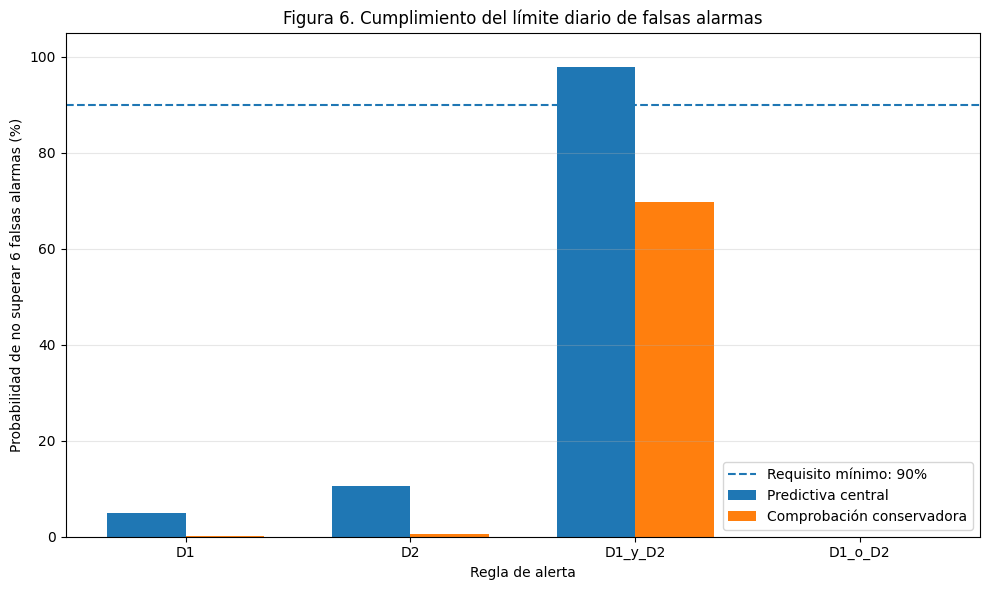

In [231]:
# Creamos los datos para la gráfica
nombres_reglas = tabla_e4["Regla"]
probabilidades_centrales = (
    tabla_e4["P(N <= 6)"] * 100
)
probabilidades_conservadoras = (
    tabla_e4["P(N <= 6) conservadora"] * 100
)

# Creamos la figura
posiciones = np.arange(len(nombres_reglas))
ancho = 0.35
plt.figure(figsize=(10, 6))

# Graficamos las probabilidades predictivas centrales
plt.bar(
    posiciones - ancho / 2,
    probabilidades_centrales,
    ancho,
    label="Predictiva central"
)

# Graficamos las probabilidades conservadoras
plt.bar(
    posiciones + ancho / 2,
    probabilidades_conservadoras,
    ancho,
    label="Comprobación conservadora"
)

# Agregamos la línea del requisito del 90%
plt.axhline(
    y=90,
    linestyle="--",
    label="Requisito mínimo: 90%"
)

# Configuramos los nombres y títulos
plt.xticks(
    posiciones,
    nombres_reglas
)

plt.ylabel("Probabilidad de no superar 6 falsas alarmas (%)")
plt.xlabel("Regla de alerta")
plt.title("Figura 6. Cumplimiento del límite diario de falsas alarmas")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()